Problem 2.22 (Linear Air Drag): The equation 2.39 in text (also provided below) describes the
range of a projectile in a linear medium, which cannot be solved analytically (paper and pencil
methods) in terms of elementary functions. If you put in numbers for the several parameters, then
it can be solved numerically using any of several software packages such as Mathematica, Maple,
and MatLab (I personally will suggest using Python 😊). To practice this, do the following:
Consider a projectile launched at angle $\theta$ above the horizontal ground with initial speed $v_0$ in a linear medium. Choose units such that $v_0 = 1$ and $g = 1$. Suppose also that the terminal speed $v_{ter} = 1$. (With $v_0 = v_{ter}$, air resistance should be fairly important.) We know that in a vacuum, the maximum range occurs at $\theta = \pi/4 \sim 0.75$. (A) What is the maximum range in a vacuum? (B)
Now solve (2.39) for the range in the given medium at the same angle $\theta = 0.75$. (C) Once you
have your calculation working, repeat it for some selection of values of $\theta$ within which the
maximum range probably lies. (You could try $\theta = 0.4, 0.5, \dots , 0.8$.) (D) Based on these results, choose a smaller interval for $\theta$ where you're sure the maximum lies and repeat the process. Repeat it again if necessary until you know the maximum range and the corresponding angle to
two significant figures (it may help to think of this as an iterative process). Compare with the
vacuum values.

$$\frac{v_{iy} + v_{term}}{v_{xi}}R + v_{term}\tau\ln\left(1 - \frac{R}{v_{xi}\tau}\right) = 0$$

**A.** Newton's 2nd Law in a vacuum gives us the equation of motion

$$
F = m\vec{a} \Longrightarrow -mg\hat{y} = m\dot{\vec{v}} \\
\Longrightarrow \int_{\vec{v_0}}^{\vec{v}} d\vec{v} = \int_0^t -g\hat{y}dt \\
\Longrightarrow \vec{v} = \frac{d\vec{r}}{dt} = \vec{v}_0 - gt\hat{y} \\
\Longrightarrow \vec{r} = \vec{r}_0 + \vec{v}_0t - \frac{1}{2}gt^2\hat{y}
$$

The range of the projectile is how far it goes until it hits the ground, meaning the y-coordinate is 0. If we call the time of impact $T$, then

$$
y = 0 = y_0 + v_{0y}T - \frac{1}{2}gT^2\\
\Longrightarrow  T = \frac{-v_{0y} - \sqrt{v_{0y}^2 - 4(-\frac{1}{2}g)(y_0)}}{2(-\frac{1}{2}g)} = \frac{v_{0y}}{g} + \frac{1}{g}\sqrt{v_{0y}^2 + 2gy_0}
$$

If the projectile was launched at an angle $\theta$ with the horizontal axis, then the initial velocity can be split into components:
$$
v_{0x} = v_0\cos\theta \\
v_{0y} = v_0\sin\theta
$$

Combining this with our assumption that $v_0 = g = 1$, the time of impact is

$$
T = \frac{1}{1}\sin\theta + \frac{1}{1}\sqrt{\sin^2\theta + 2gy_0}
$$

And if we place our origin at the projectile's initial position $y_0 = 0$, so 

$$
T = \sin\theta + \sin\theta = 2\sin\theta
$$

This is finally something I'm comfortable plugging in, so let's check what the $x$ coordinate is at time of impact. 

$$
x(T) = x_0 + v_{0x}T = 0 + \cos\theta\left(2\sin\theta \right) = 2\sin\theta\cos\theta = \sin2\theta \\ \\
\boxed{R = \sin2\theta}
$$

The maximum value will occur when $\sin2\theta = 1$, or when $2\theta = \pi/2 \Longrightarrow \theta = \pi/4$. 

Thus the maximum range of a projectile in a vacuum is

$$
R_{max} = m\sin\left(2\frac{\pi}{4}\right) = \sin(\pi/2) = 1
$$

**B.** Given equation 2.39 we can plug in our assumptions to get a simplified equation. Also, the time constant $\tau$ can shown to be $\tau = v_{ter}/g$, which by our substitutions is $\tau = 1/1 = 1$. So finally we have

$$
\frac{\sin\theta + 1}{\cos\theta}R + \ln\left(1 - \frac{R}{\cos\theta}\right) = 0 \\
$$

In [2]:
import scipy as sp
import numpy as np


theta = np.pi / 4
func = lambda R: (np.sin(theta) + 1) / np.cos(theta) * R + np.log(1 - R / np.cos(theta))

R_solution = sp.optimize.fsolve(func, 0.5)
print(f"The range of the projectile is: {R_solution[0]}")

The range of the projectile is: 0.49098635926746664


C:\Users\tjp05\AppData\Local\Temp\ipykernel_14012\3261530796.py:8: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  R_solution = sp.optimize.fsolve(func, 0.5)
C:\Users\tjp05\AppData\Local\Temp\ipykernel_14012\3261530796.py:7: RuntimeWarning: invalid value encountered in log
  func = lambda R: (np.sin(angle) + 1) / np.cos(angle) * R + np.log(1 - R / np.cos(angle))


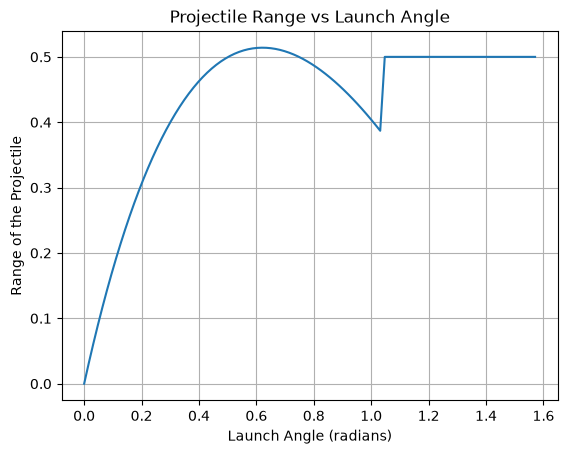

In [28]:
import matplotlib.pyplot as plt

def plot_range_vs_angle(theta: np.ndarray):

    R_solutions = []
    for angle in theta:
        func = lambda R: (np.sin(angle) + 1) / np.cos(angle) * R + np.log(1 - R / np.cos(angle))
        R_solution = sp.optimize.fsolve(func, 0.5)
        R_solutions.append(R_solution[0])

    plt.plot(theta, R_solutions)
    plt.xlabel('Launch Angle (radians)')
    plt.ylabel('Range of the Projectile')
    plt.title('Projectile Range vs Launch Angle')
    plt.grid()
    plt.show()

theta_1 = np.linspace(0, np.pi / 2, 100)
plot_range_vs_angle(theta_1)

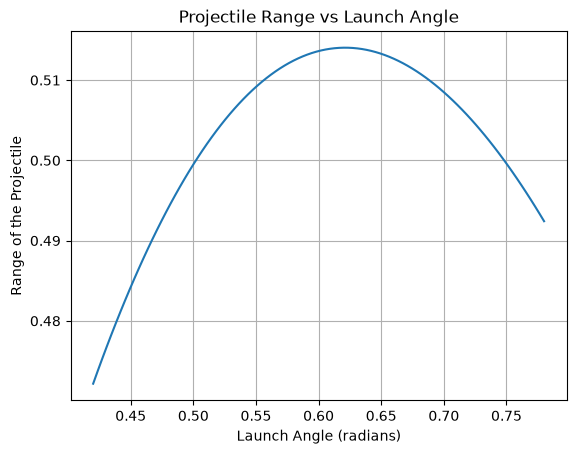

In [29]:
theta_2 = np.linspace(0.42, 0.78, 100)
plot_range_vs_angle(theta_2)

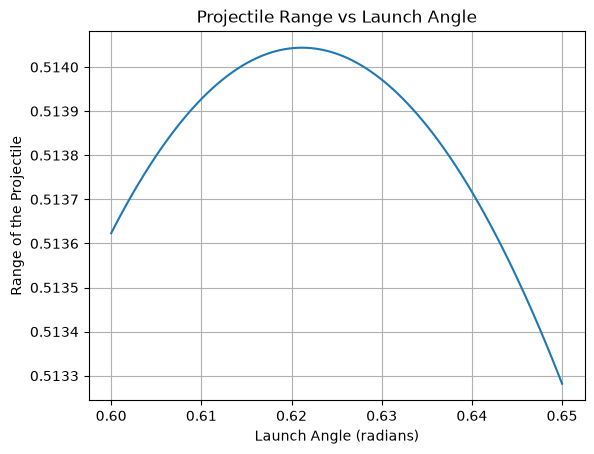

In [30]:
theta_3 = np.linspace(0.6, 0.65, 100)
plot_range_vs_angle(theta_3)

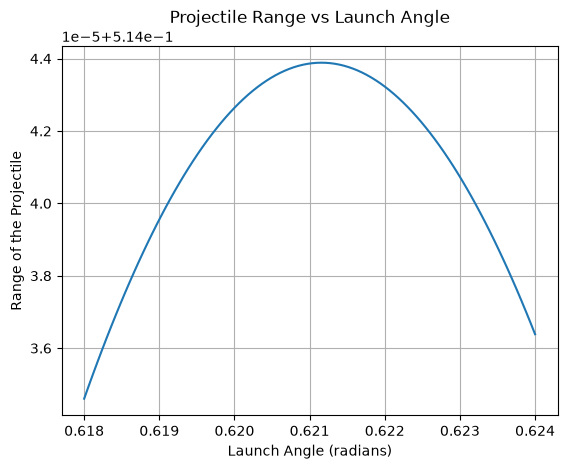

In [31]:
theta_4 = np.linspace(0.618, 0.624, 100)
plot_range_vs_angle(theta_4)

C:\Users\tjp05\AppData\Local\Temp\ipykernel_14012\3225880898.py:8: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  R_solution = sp.optimize.fsolve(func, 0.5)
C:\Users\tjp05\AppData\Local\Temp\ipykernel_14012\3225880898.py:7: RuntimeWarning: invalid value encountered in log
  func = lambda R: (np.sin(angle) + 1) / np.cos(angle) * R + np.log(1 - R / np.cos(angle))


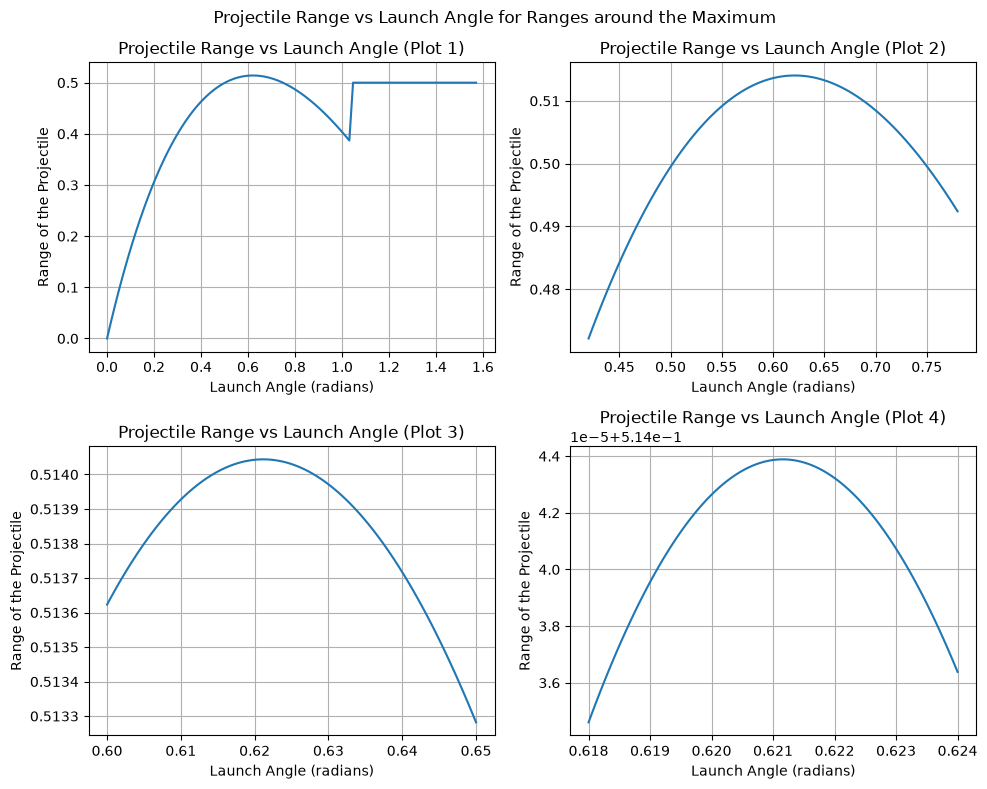

The maximum range occurs at a launch angle of approximately 0.62 radians.
The maximum range is approximately 0.51.


In [41]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

thetas = [theta_1, theta_2, theta_3, theta_4]
for k, (ax, theta) in enumerate(zip(axes.flat, thetas)):
    R_solutions = []
    for angle in theta:
        func = lambda R: (np.sin(angle) + 1) / np.cos(angle) * R + np.log(1 - R / np.cos(angle))
        R_solution = sp.optimize.fsolve(func, 0.5)
        R_solutions.append(R_solution[0])

    ax.plot(theta, R_solutions)
    ax.set_xlabel('Launch Angle (radians)')
    ax.set_ylabel('Range of the Projectile')
    ax.set_title(f'Projectile Range vs Launch Angle (Plot {k + 1})')
    ax.grid()

plt.suptitle('Projectile Range vs Launch Angle for Ranges around the Maximum')
plt.tight_layout()
plt.show()

max_launch_angle = theta_4[np.argmax(R_solutions)]
max_range = np.max(R_solutions)
print(f"The maximum range occurs at a launch angle of approximately {max_launch_angle:.2f} radians.")
print(f"The maximum range is approximately {max_range:.2f}.")

With drag the max range is 0.51 at an angle of 0.62 radians, which is about half the range in a vacuum 1.0, ocurring at $\frac{\pi}{4} \approx 0.79$ radians. The air drag necessitates the projectile spend less time in the air subject to the resistive force. 